# 04 — Denoising e bordas (Fase 4)

> **Aviso:** experimento didático com partição própria; não comparável ao benchmark oficial do MVTec AD.

Este notebook só lê `results/fase4/` (gerado por `python scripts/run_fase4.py`). A única parte que abre imagens é o exemplo visual opcional, no fim da seção 4.

## 1. Objetivo e perguntas

O baseline da Fase 3 tem precisão alta, recall baixo e 30 a 40 componentes por imagem, a maioria arcos finos nos anéis. A Fase 1 mediu ruído de sensor desprezível (σ ≈ 0,6 nível). Então o filtro aqui **não** serve para tirar ruído: serve para reduzir a diferença espúria entre a imagem e a referência (desalinhamento residual de 1 a 3 px, reflexos, textura fina do vidro) sem apagar o defeito.

**Perguntas:**

- **A.** Qual filtro melhora mais a separação entre defeito e normal?
- **B.** Normalizar o brilho de cada imagem resolve os falsos positivos extras das boas do teste (achado da Fase 2)?
- **C.** O gradiente (Sobel) acrescenta informação ao mapa de intensidade nas quebras?
- **D.** As bordas novas do Canny servem para a segmentação?

## 2. Hipóteses e critérios (definidos antes do teste)

| | Hipótese | Critério de decisão |
|---|---|---|
| A. Denoising | O **Gaussiano** deve vencer: desalinhamento de 1 a 2 px vira diferença pequena depois do borramento. Mediana e bilateral preservam bordas, inclusive as dos anéis desalinhados, que são a fonte do erro. Teto: σ ≤ 3 px, bem abaixo do raio do menor defeito (~11 px). | AUROC de pixel no desenvolvimento. Diferença < 0,01 é empate, e no empate vence o mais simples. |
| B. Brilho | Se as boas do teste são ~2 níveis mais claras, igualar o brilho médio deveria reduzir os falsos positivos nelas. | Adotar só se não piorar a AUROC. Os falsos positivos nas boas da avaliação são só registro. |
| C. Sobel | Quebras criam bordas que não existem na garrafa normal; o z do gradiente deve ajudar em `broken_*`. | Adotar se a AUROC média das quebras subir mais de 0,01 **sem** perder mais de 0,01 em `contamination`. |
| D. Canny | Bordas novas (presentes na imagem, ausentes na referência) deveriam cair dentro dos defeitos. | Informativo: fração das bordas novas dentro do defeito e quantas aparecem em garrafas boas. |

Uma mudança por vez, o resto fixo. Decisões só com calibração e desenvolvimento.

## 3. O que foi feito

- **Filtros:** `preprocess.denoise` (nenhum, Gaussiano σ ∈ {1, 2, 3}, mediana 5×5, bilateral). Para cada candidato, a referência é refeita com as imagens filtradas.
- **Protocolo único:** `pipeline.load_dataset` carrega e alinha; `pipeline.evaluate_map` calcula, para qualquer mapa de anomalia, o limiar (percentil 99,5 nas boas de calibração), a AUROC de pixel geral e por tipo, Dice, precisão e recall no desenvolvimento e os componentes espúrios por garrafa boa de calibração. Assim todas as variantes são medidas do mesmo jeito.
- **Sobel:** `preprocess.sobel_magnitude` (conferido nos testes contra `sobel_magnitude_numpy`, que usa a convolução feita à mão em `convolve2d`). O mapa z do gradiente usa o mesmo `reference.ReferenceModel`, aplicado à pilha de gradientes. Combinações testadas: soma e máximo com o z de intensidade.
- **Canny:** `preprocess.canny_new_edges`, bordas da imagem fora das bordas da referência dilatadas em 2 px, nas razões T_H:T_L de 2:1 e 3:1.

In [ ]:
import pandas as pd
from IPython.display import Image, display
from pdi_defeitos import viz
from pdi_defeitos.config import load_config

cfg = load_config()
res = cfg['root'] / 'results' / 'fase4'

den = pd.read_csv(res / 'denoising.csv').set_index('filtro')
norm = pd.read_csv(res / 'normalizacao.csv')
bordas = pd.read_csv(res / 'bordas.csv').set_index('mapa')
canny = pd.read_csv(res / 'canny.csv').set_index('razao')

COLS = {'auroc': 'AUROC', 'auroc_broken_large': 'AUROC broken_large', 'auroc_broken_small': 'AUROC broken_small',
        'auroc_contamination': 'AUROC contamination', 'dice': 'Dice', 'precision': 'precisão', 'recall': 'recall',
        'cal_components': 'componentes espúrios por boa'}
FILTROS = {'none': 'sem filtro', 'gaussian(sigma=1)': 'Gaussiano σ=1', 'gaussian(sigma=2)': 'Gaussiano σ=2',
           'gaussian(sigma=3)': 'Gaussiano σ=3', 'median(ksize=5)': 'mediana 5×5',
           'bilateral(d=9,sigma_color=30,sigma_space=3)': 'bilateral (d=9)'}
print('Candidatos (config.yaml):', len(cfg['denoise_candidates']), '| empate: diferença de AUROC <', viz.fmt_br(cfg['decision_tie']))

Candidatos (config.yaml): 6 | empate: diferença de AUROC < 0,01


## 4. Resultados

### 4.A Comparação dos filtros

In [ ]:
tab_den = den[list(COLS)].rename(index=FILTROS, columns=COLS)
tab_den.index.name = None
viz.fmt_table(tab_den, mark='Gaussiano σ=2')

,AUROC,AUROC broken_large,AUROC broken_small,AUROC contamination,Dice,precisão,recall,componentes espúrios por boa
sem filtro,"0,83","0,75","0,85","0,91","0,52","0,86","0,40","16,87"
Gaussiano σ=1,"0,87","0,79","0,90","0,93","0,58","0,87","0,46","7,80"
Gaussiano σ=2 ← escolhido,"0,89","0,83","0,92","0,94","0,64","0,86","0,53","4,13"
Gaussiano σ=3,"0,89","0,83","0,92","0,95","0,67","0,85","0,57","3,10"
mediana 5×5,"0,87","0,80","0,90","0,93","0,57","0,88","0,44","8,23"
bilateral (d=9),"0,88","0,81","0,91","0,94","0,60","0,88","0,47","8,73"


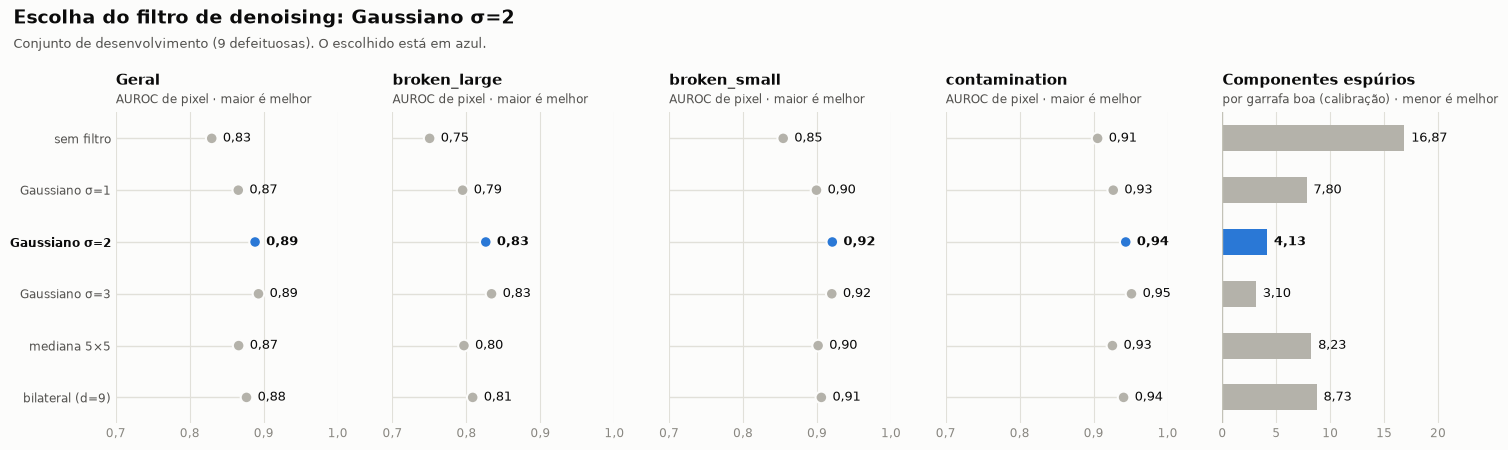

In [ ]:
fig = viz.filter_choice(
    list(tab_den.index),
    {'Geral': den.auroc, 'broken_large': den.auroc_broken_large, 'broken_small': den.auroc_broken_small, 'contamination': den.auroc_contamination},
    den.cal_components, highlight=list(den.index).index('gaussian(sigma=2)'),
    title='Escolha do filtro de denoising: Gaussiano σ=2',
    subtitle='Conjunto de desenvolvimento (9 defeituosas). O escolhido está em azul.')

In [ ]:
# Desempate σ=2 × σ=3, pela regra definida antes
melhor = den.auroc.max()
empatados = den[den.auroc >= melhor - cfg['decision_tie']]
print('Melhor AUROC:', viz.fmt_br(melhor, 4), f'({FILTROS[den.auroc.idxmax()]})')
print('Empatados (diferença < 0,01):', ', '.join(f'{FILTROS[k]} = {viz.fmt_br(v, 4)}' for k, v in empatados.auroc.items()))
print('Diferença σ=3 − σ=2:', viz.fmt_br(den.auroc['gaussian(sigma=3)'] - den.auroc['gaussian(sigma=2)'], 4))

Melhor AUROC: 0,8928 (Gaussiano σ=3)
Empatados (diferença < 0,01): Gaussiano σ=2 = 0,8882, Gaussiano σ=3 = 0,8928
Diferença σ=3 − σ=2: 0,0046


**Leitura.** A hipótese se confirmou para σ ≥ 2: o Gaussiano σ=2 e o σ=3 (0,89) ficam acima da mediana (0,87) e do bilateral (0,88); o σ=1 empata com os dois. Todo filtro melhora o baseline. A AUROC sobe de 0,83 (sem filtro) para 0,89 e os componentes espúrios por garrafa boa caem de 16,87 para 4,13.

**Desempate σ=2 × σ=3.** O σ=3 tem a maior AUROC (0,8928), mas a diferença para o σ=2 (0,8882) é de 0,0046, menor que o empate de 0,01 definido antes. Com 9 imagens de desenvolvimento, essa diferença não é evidência. No empate vence o mais simples, aqui o σ menor: borra menos e tem menos risco de apagar os defeitos pequenos (o menor tem ~22 px de diâmetro). O σ=3 também já mostra o custo: a precisão cai de 0,86 para 0,85 e a AUROC de `broken_small` para de subir.

**Decisão A:** Gaussiano σ=2.

### 4.B Normalização de brilho

Com o filtro escolhido, com e sem igualar o brilho médio da garrafa ao da referência. As duas últimas colunas são **registro da avaliação, não usado para decidir**.

In [ ]:
tab_norm = norm.set_index(norm.normalizar_brilho.map({False: 'sem normalizar', True: 'normalizando o brilho'}))
tab_norm = tab_norm[['auroc', 'dice', 'cal_components']].rename(columns=COLS).join(
    (100 * tab_norm[['fp_frac_good_train', 'fp_frac_good_test']]).set_axis(
        ['FP nas boas do treino (% da garrafa, registro)', 'FP nas boas do teste (% da garrafa, registro)'], axis=1))
tab_norm.index.name = None
print('Diferença de AUROC ao normalizar:', viz.fmt_br(norm.auroc[1] - norm.auroc[0], 3))
viz.fmt_table(tab_norm, mark='sem normalizar')

Diferença de AUROC ao normalizar: -0,014


,AUROC,Dice,componentes espúrios por boa,"FP nas boas do treino (% da garrafa, registro)","FP nas boas do teste (% da garrafa, registro)"
sem normalizar ← escolhido,"0,89","0,64","4,13","0,37","0,95"
normalizando o brilho,"0,87","0,64","5,63","0,46","0,92"


**Leitura.** A hipótese foi refutada. Normalizar piora a AUROC em 0,014 (mais que o empate) e aumenta os componentes espúrios. No registro, os falsos positivos das boas do teste quase não mudam (0,95% → 0,92%) e os das boas do treino pioram (0,37% → 0,46%). A causa dos falsos positivos extras nas boas do teste é local (reflexos, anéis), não o brilho médio.

**Decisão B:** não normalizar.

### 4.C Bordas por Sobel: intensidade × gradiente × soma × máximo

Mapas comparados, todos com o Gaussiano σ=2: z de intensidade (o da decisão A), z da magnitude do gradiente e as duas combinações.

In [ ]:
MAPAS = {'intensidade': 'intensidade', 'gradiente': 'gradiente (Sobel)', 'soma': 'soma', 'maximo': 'máximo'}
tab_b = bordas[list(COLS)].rename(index=MAPAS, columns=COLS)
tab_b.index.name = None
viz.fmt_table(tab_b, mark='máximo')

,AUROC,AUROC broken_large,AUROC broken_small,AUROC contamination,Dice,precisão,recall,componentes espúrios por boa
intensidade,"0,89","0,83","0,92","0,94","0,64","0,86","0,53","4,13"
gradiente (Sobel),"0,71","0,68","0,77","0,68","0,39","0,75","0,29","17,50"
soma,"0,90","0,85","0,92","0,93","0,60","0,83","0,49","11,13"
máximo ← escolhido,"0,90","0,85","0,93","0,94","0,63","0,83","0,53","11,83"


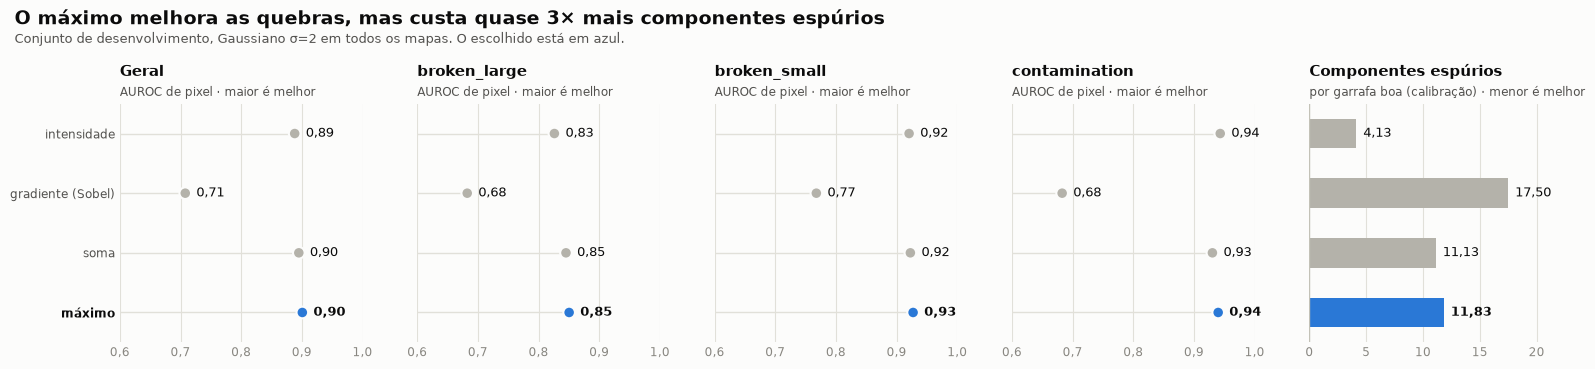

In [ ]:
fig = viz.hpanels(
    list(tab_b.index),
    [{'kind': 'dot', 'xlim': (0.6, 1.0), 'title': t, 'note': 'AUROC de pixel · maior é melhor', 'values': bordas[c]}
     for t, c in [('Geral', 'auroc'), ('broken_large', 'auroc_broken_large'), ('broken_small', 'auroc_broken_small'), ('contamination', 'auroc_contamination')]]
    + [{'title': 'Componentes espúrios', 'note': 'por garrafa boa (calibração) · menor é melhor', 'values': bordas.cal_components}],
    highlight=list(bordas.index).index('maximo'),
    title='O máximo melhora as quebras, mas custa quase 3× mais componentes espúrios',
    subtitle='Conjunto de desenvolvimento, Gaussiano σ=2 em todos os mapas. O escolhido está em azul.')

In [ ]:
# A regra definida antes, aplicada a cada mapa em relação ao de intensidade
quebras = (bordas.auroc_broken_large + bordas.auroc_broken_small) / 2
regra = pd.DataFrame({
    'ganho na AUROC média das quebras': quebras - quebras['intensidade'],
    'variação na AUROC de contamination': bordas.auroc_contamination - bordas.auroc_contamination['intensidade'],
    'componentes espúrios (× intensidade)': bordas.cal_components / bordas.cal_components['intensidade'],
})
tie = cfg['decision_tie']
regra['aprovado pela regra'] = (regra.iloc[:, 0] > tie) & (regra.iloc[:, 1] >= -tie)
regra = regra.drop(index='intensidade')
aprovados = bordas.auroc[regra.index[regra['aprovado pela regra']]]   # usado na conferência do item 5
regra = regra.rename(index=MAPAS)
regra.index.name = None
viz.fmt_table(regra, decimals=3, mark='máximo')

,ganho na AUROC média das quebras,variação na AUROC de contamination,componentes espúrios (× intensidade),aprovado pela regra
gradiente (Sobel),"-0,148","-0,261","4,234",não
soma,"0,011","-0,013","2,694",não
máximo ← escolhido,"0,015","-0,003","2,863",sim


**Leitura.**

- O gradiente sozinho é bem pior que a intensidade (AUROC 0,71 × 0,89): as bordas dos anéis variam muito entre garrafas boas.
- A soma melhora as quebras no limite da regra, mas perde 0,013 em `contamination`: reprovada.
- O **máximo** é o único aprovado: +0,015 na média das quebras (+0,024 em `broken_large`) e −0,003 em `contamination`, dentro do empate. A AUROC geral vai de 0,89 para 0,90.

**O custo, explícito:** os componentes espúrios por garrafa boa sobem de 4,13 para 11,83 (2,9×), e o Dice não melhora (0,64 → 0,63). O ganho está na ordenação dos pixels (AUROC), não na máscara com o limiar atual.

**Decisão C:** adotar o máximo, **condicionado**. A Fase 5 avalia os dois mapas (intensidade e máximo) e a morfologia da Fase 6 decide: fica o mapa com menos falsos positivos e recall igual ou maior depois da limpeza. Se o máximo não passar, o pipeline volta ao mapa só de intensidade.

### 4.D Bordas novas do Canny

In [ ]:
tab_c = canny.rename(columns={
    'frac_bordas_novas_dentro_do_defeito': 'fração das bordas novas dentro do defeito',
    'defeitos_com_borda_nova': 'fração dos defeitos com alguma borda nova',
    'cobertura_broken_large': 'cobertura broken_large', 'cobertura_broken_small': 'cobertura broken_small',
    'cobertura_contamination': 'cobertura contamination',
    'px_borda_nova_por_boa_calib': 'px de borda nova por garrafa boa',
    'componentes_por_boa_calib': 'componentes por garrafa boa'})
tab_c.index.name = 'razão T_H:T_L'
viz.fmt_table(tab_c).T

razão T_H:T_L,2:1,3:1
fração das bordas novas dentro do defeito,"0,15","0,18"
fração dos defeitos com alguma borda nova,"0,89","0,89"
cobertura broken_large,"0,03","0,04"
cobertura broken_small,"0,08","0,08"
cobertura contamination,"0,02","0,02"
px de borda nova por garrafa boa,"958,87","794,70"
componentes por garrafa boa,"15,00","20,03"


**Leitura.** Só 15 a 18% das bordas novas caem dentro de um defeito; as outras 82 a 85% são bordas de anéis e reflexos que escaparam da tolerância de 2 px. Cada garrafa **boa** tem de 795 a 959 px de borda nova, em 15 a 20 componentes. As bordas que acertam cobrem só 2 a 8% da área do defeito.

**Decisão D:** Canny descartado como entrada da segmentação.

### 4.E Mapas no desenvolvimento

Colunas: imagem filtrada (Gaussiano σ=2), z de intensidade, z do gradiente e ground truth. Os mapas estão saturados em 2× o limiar de cada um.

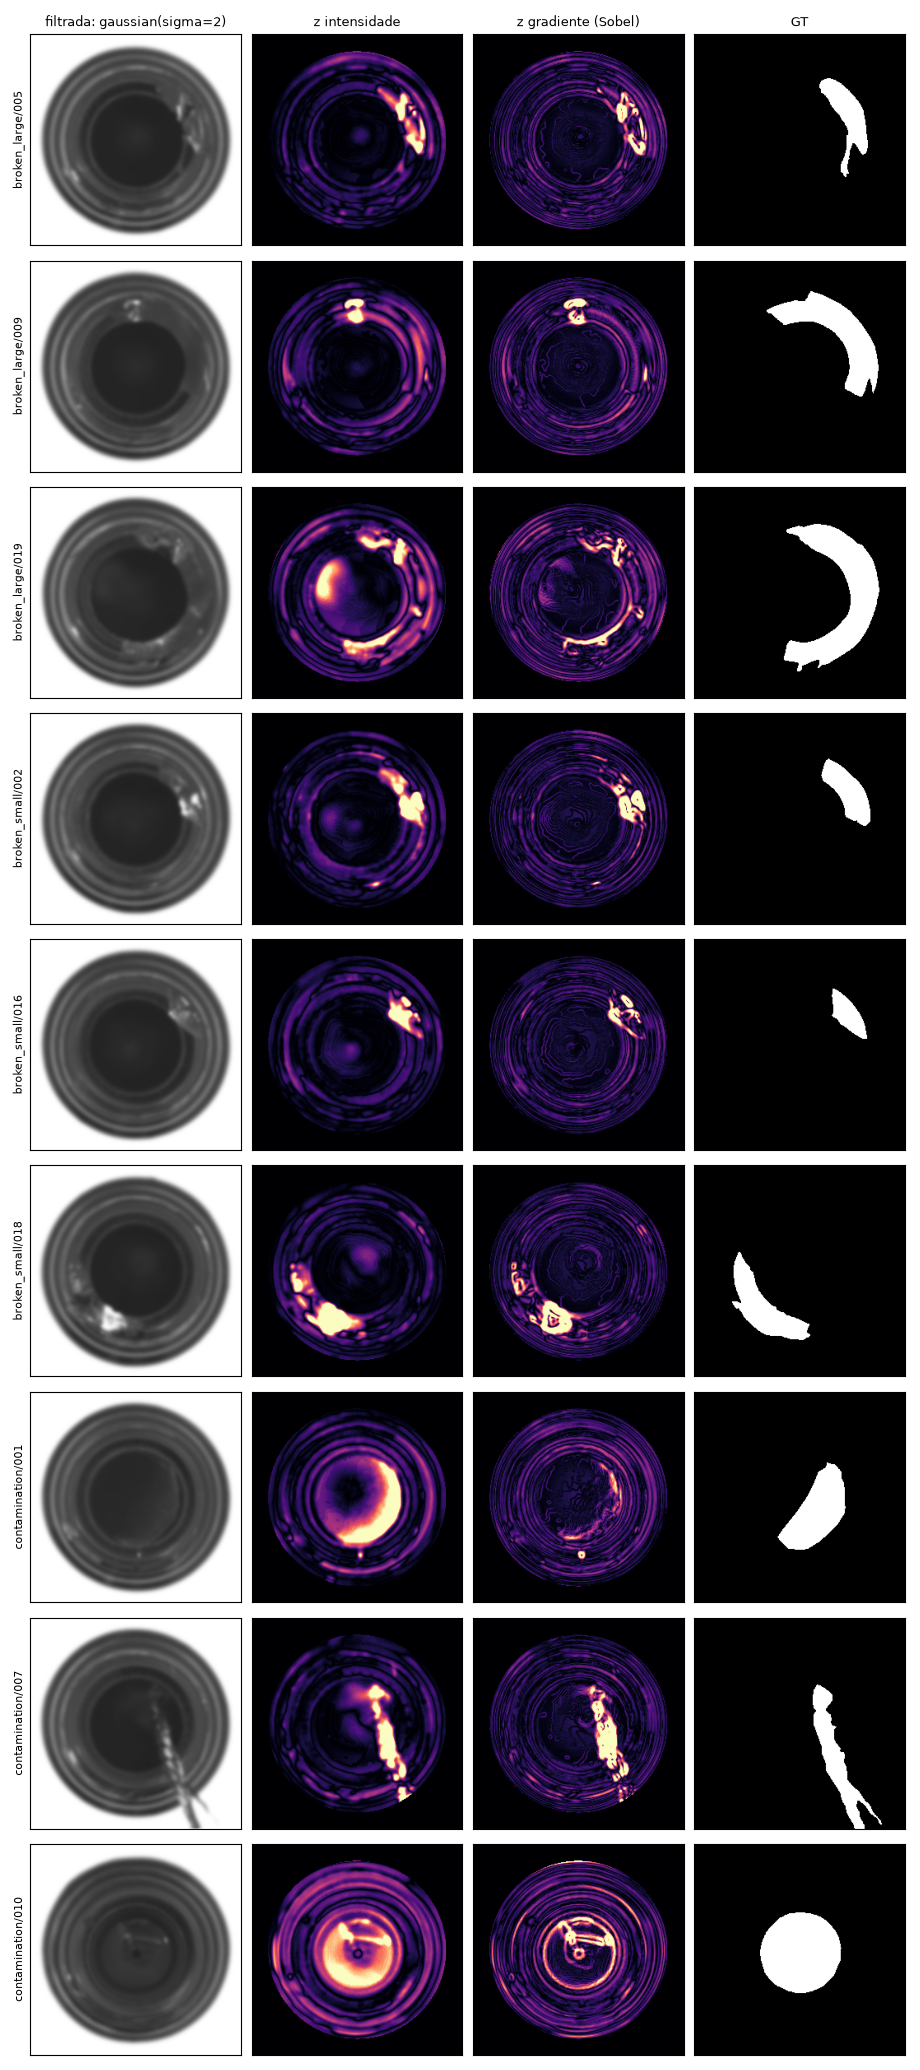

In [ ]:
display(Image(res / 'mapas_desenvolvimento.png'))

### 4.F Progresso: baseline → + Gaussiano → + Sobel

In [ ]:
etapas = {'Baseline (sem filtro)': den.loc['none'], '+ Gaussiano σ=2 (intensidade)': bordas.loc['intensidade'], '+ Sobel (máximo)': bordas.loc['maximo']}
prog = pd.DataFrame({k: v[['auroc', 'dice', 'recall', 'cal_components']] for k, v in etapas.items()}).astype(float)
prog.index = ['AUROC de pixel', 'Dice', 'Recall', 'Componentes espúrios por garrafa boa (calibração)']
viz.fmt_table(prog)

,Baseline (sem filtro),+ Gaussiano σ=2 (intensidade),+ Sobel (máximo)
AUROC de pixel,"0,83","0,89","0,90"
Dice,"0,52","0,64","0,63"
Recall,"0,40","0,53","0,53"
Componentes espúrios por garrafa boa (calibração),"16,87","4,13","11,83"


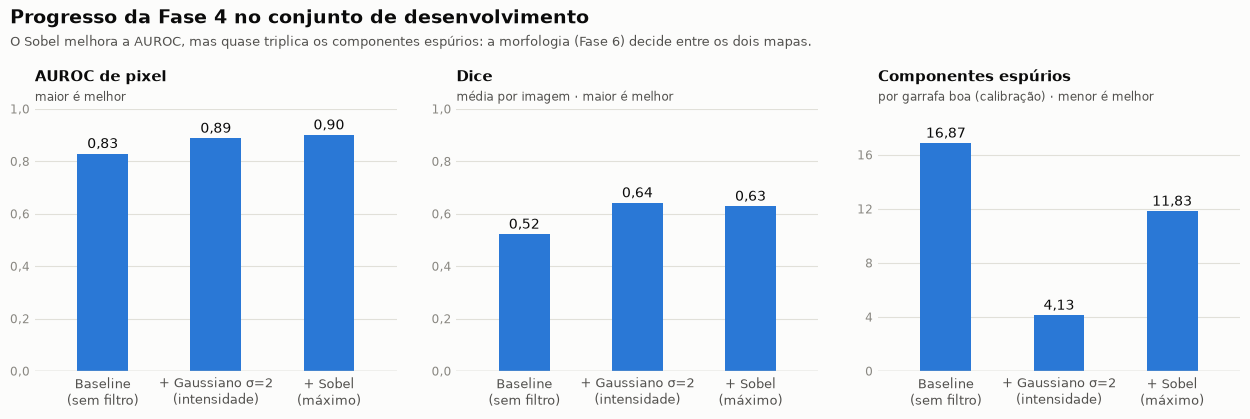

In [ ]:
fig = viz.progress(
    ['Baseline\n(sem filtro)', '+ Gaussiano σ=2\n(intensidade)', '+ Sobel\n(máximo)'],
    [('AUROC de pixel', 'maior é melhor', prog.loc['AUROC de pixel'], 1.0),
     ('Dice', 'média por imagem · maior é melhor', prog.loc['Dice'], 1.0),
     ('Componentes espúrios', 'por garrafa boa (calibração) · menor é melhor', prog.iloc[3], None)],
    title='Progresso da Fase 4 no conjunto de desenvolvimento',
    subtitle='O Sobel melhora a AUROC, mas quase triplica os componentes espúrios: a morfologia (Fase 6) decide entre os dois mapas.')

### Exemplo visual (opcional, precisa do dataset)

Uma defeituosa do desenvolvimento: imagem em cinza, depois do Gaussiano escolhido, magnitude do Sobel e bordas do Canny (3:1). Sem o dataset, a célula avisa e é pulada.

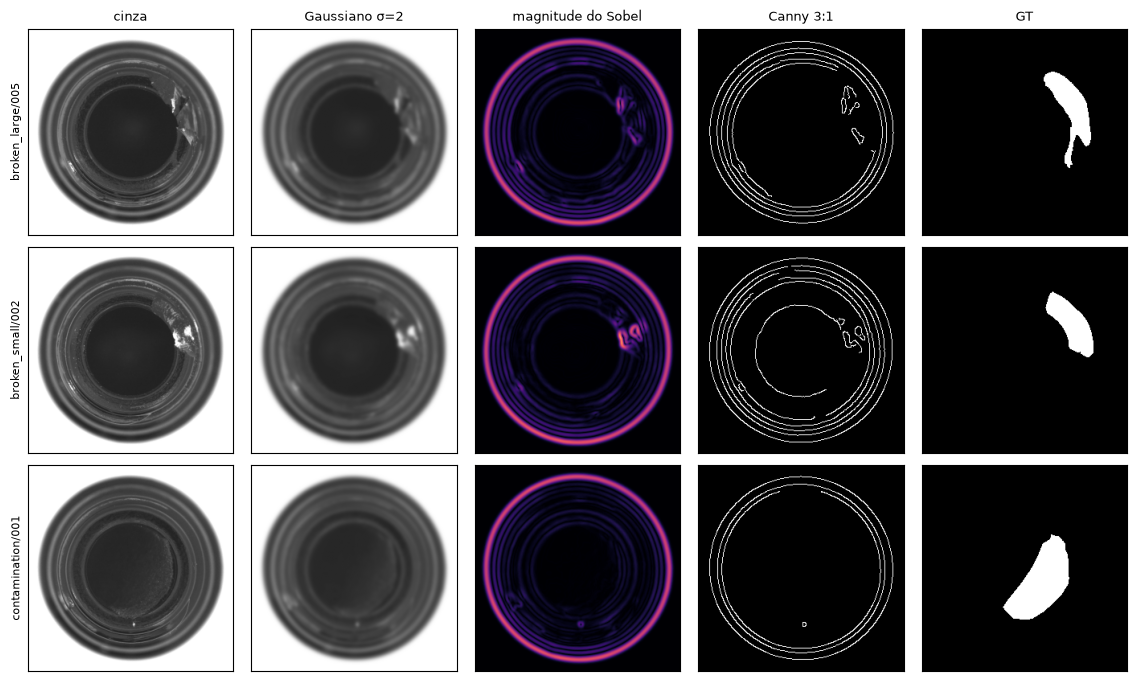

In [ ]:
if viz.dataset_available(cfg['category_dir']):
    import cv2
    from pdi_defeitos.io import list_samples, load_sample
    from pdi_defeitos.preprocess import denoise, sobel_magnitude
    from pdi_defeitos.split import load_partition

    part = load_partition(cfg['root'] / 'results' / 'fase2' / 'particao.csv', list_samples(cfg['category_dir']))
    linhas, nomes = [], []
    for _, row in part[part.role == 'development'].groupby('defect_type').head(1).iterrows():
        img, mask = load_sample(row, size=cfg['image']['size'])
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        filtrada = denoise(gray, **cfg['pipeline']['denoise'])
        alto = cfg['edges']['canny_high']
        linhas.append([gray, filtrada, sobel_magnitude(filtrada), cv2.Canny(filtrada, alto / 3, alto, L2gradient=True), mask])
        nomes.append(row.sample_id.split('/', 1)[1])
    fig = viz.panel_grid(linhas, nomes, ['cinza', 'Gaussiano σ=2', 'magnitude do Sobel', 'Canny 3:1', 'GT'],
                         cmaps=['gray', 'gray', 'magma', 'gray', 'gray'], vmax=[255, 255, 400, 255, 1])

## 5. Leitura geral e decisões

| | Decisão | Por quê |
|---|---|---|
| A. Denoising | **Gaussiano σ=2** | AUROC 0,83 → 0,89; empate com σ=3 (diferença de 0,005), vence o menor |
| B. Brilho | **Não normalizar** | Piora a AUROC (−0,014) e não reduz os falsos positivos nas boas do teste |
| C. Bordas | **Máximo entre z de intensidade e z do gradiente (Sobel)**, condicionado | Aprovado pela regra: melhora as quebras sem perder em `contamination`. Custa ~3× mais componentes espúrios |
| D. Canny | **Descartado** | 82 a 85% das bordas novas ficam fora dos defeitos |

As decisões estão registradas na seção `pipeline` do `config.yaml`. A célula abaixo confere se o que os CSVs mostram bate com o que está registrado.

In [ ]:
p = cfg['pipeline']
pelos_csvs = {
    'denoise': empatados.index.min(),                                              # A: entre os empatados, o menor σ
    'normalize_brightness': bool(norm.auroc[1] >= norm.auroc[0] - tie),            # B: só se não piorar a AUROC
    'anomaly_map': aprovados.idxmax() if len(aprovados) else 'intensidade',        # C: aprovado pela regra
}
pelos_csvs['anomaly_maps_fase5'] = ['intensidade', pelos_csvs['anomaly_map']]      # condição da decisão C
no_config = {**p, 'denoise': '{method}(sigma={sigma})'.format(**p['denoise'])}
conf = pd.DataFrame({'config.yaml': {k: str(no_config.get(k)) for k in pelos_csvs}, 'pelos CSVs': {k: str(v) for k, v in pelos_csvs.items()}})
conf['bate'] = conf['config.yaml'] == conf['pelos CSVs']
assert conf.bate.all(), 'config.yaml e CSVs discordam'
viz.fmt_table(conf)

,config.yaml,pelos CSVs,bate
denoise,gaussian(sigma=2),gaussian(sigma=2),sim
normalize_brightness,False,False,sim
anomaly_map,maximo,maximo,sim
anomaly_maps_fase5,"['intensidade', 'maximo']","['intensidade', 'maximo']",sim


## 6. Como isso orienta a próxima fase

- **Fase 5 (segmentação):** roda com os **dois** mapas (`anomaly_maps_fase5: [intensidade, maximo]`). O recall ainda é baixo (0,53) com precisão alta (0,83 a 0,86), então a prioridade do Método A é o crescimento por histerese: partir dos pixels acima do limiar e crescer para os vizinhos acima de um limiar menor.
- **Fase 6 (morfologia):** decide entre os dois mapas. A abertura deve tirar os arcos finos que o Sobel acrescentou; fica o mapa com menos falsos positivos e recall igual ou maior depois da limpeza.
- **Risco registrado:** a parte escura das quebras grandes não aparece em nenhum dos mapas (`broken_large` tem a menor AUROC, 0,85). Se a histerese e o fechamento não resolverem, isso vira uma limitação documentada da abordagem por referência.